# Власне донавчання: маршрутизація українських звернень
Користувач — оператор підтримки. Вхід — текст, вихід — одна з п’яти категорій. Класифікатор має стабільний формат, не потребує довгого промпту та дешевший за генеративну модель. RAG не навчає межі класів. DistilBERT multilingual — компактний базовий енкодер із новою головою. Дані синтетичні, створені для роботи, CC0; не містять персональних даних. Обмеження: шаблонні дані не гарантують якість на реальних зверненнях.

In [1]:
%pip -q install "transformers>=4.48,<5" datasets accelerate scikit-learn

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [2]:
import random,time,torch,numpy as np,pandas as pd,matplotlib.pyplot as plt
from transformers import AutoTokenizer,AutoModelForSequenceClassification,Trainer,TrainingArguments,DataCollatorWithPadding,set_seed
from datasets import Dataset
from sklearn.metrics import accuracy_score,f1_score,classification_report
set_seed(42)
assert torch.cuda.is_available(), "Увімкніть GPU T4"
print(torch.cuda.get_device_name())
labels=['Авторизація','Оплата','Технічна проблема','Налаштування','Пропозиція']
phrases=[['Не можу увійти','Забув пароль','Не надходить код входу','Акаунт заблоковано','Не працює двофакторний вхід','Сесія постійно завершується','Не приймає логін','Не можу відновити доступ','Пише неправильний пароль','Не пускає в особистий кабінет'],['Двічі списали кошти','Не проходить платіж','Потрібне повернення грошей','Не отримав квитанцію','Картку відхилено','Неправильна сума рахунку','Не можу оплатити підписку','Гроші списано без замовлення','Де мій рахунок','Не зараховано оплату'],['Сайт видає помилку 500','Сторінка не завантажується','Застосунок зависає','Кнопка не реагує','Файл не завантажується','Пошук не працює','Екран стає білим','Сервіс аварійно закривається','Зображення не відображаються','Запит завершується таймаутом'],['Як змінити електронну пошту','Хочу оновити номер телефону','Як вимкнути сповіщення','Де змінити мову','Як змінити аватар','Хочу налаштувати приватність','Як відредагувати ім’я','Де вибрати часовий пояс','Як увімкнути темну тему','Хочу змінити адресу профілю'],['Додайте експорт у PDF','Пропоную новий фільтр','Було б добре мати календар','Хочу функцію групового чату','Пропоную додати сортування','Зробіть інтеграцію з поштою','Додайте підтримку нових форматів','Хотілося б бачити статистику','Пропоную покращити меню','Додайте можливість створювати шаблони']]
wrappers=['{}','Вітаю! {}','Підкажіть, будь ласка: {}','Маю питання: {}','Допоможіть: {}','Добрий день, {}','Звертаюся щодо проблеми: {}','Потрібна допомога. {}','Прошу розглянути: {}','Буду вдячний за відповідь: {}']
rows={k:[] for k in ['train','validation','test']}
for label,items in enumerate(phrases):
 for i,text in enumerate(items):
  split='train' if i<6 else 'validation' if i<8 else 'test'
  for w in wrappers: rows[split].append({'text':w.format(text),'label':label})
for k,v in rows.items(): print(k,len(v))
assert len({r['text'] for v in rows.values() for r in v})==500
print(pd.DataFrame(rows['train']).sample(5,random_state=42))

Tesla T4
train 300
validation 100
test 100
                                                  text  label
203                Маю питання: Як вимкнути сповіщення      3
266  Звертаюся щодо проблеми: Було б добре мати кал...      4
152            Підкажіть, будь ласка: Кнопка не реагує      2
9            Буду вдячний за відповідь: Не можу увійти      0
233          Маю питання: Хочу налаштувати приватність      3


## 1.2–1.3. Поділ і базовий рівень
300/100/100; різні основні формулювання в кожному наборі, щоб варіанти одного шаблону не перетиналися. Accuracy і macro F1 оцінюють загальну точність і рівномірність якості між класами. Базовий рівень — найчастіший клас (при рівності перший).

In [3]:
checkpoint='distilbert/distilbert-base-multilingual-cased'
tok=AutoTokenizer.from_pretrained(checkpoint)
ds={k:Dataset.from_list(v).map(lambda b:tok(b['text'],truncation=True,max_length=96),batched=True) for k,v in rows.items()}
y=np.array(ds['test']['label']); majority=np.bincount(ds['train']['label']).argmax(); before=np.full(len(y),majority)
def metrics(y,p): return {'accuracy':accuracy_score(y,p),'f1':f1_score(y,p,average='macro',zero_division=0)}
base=metrics(y,before); print(base)
model=AutoModelForSequenceClassification.from_pretrained(checkpoint,num_labels=5,id2label=dict(enumerate(labels)),label2id={v:i for i,v in enumerate(labels)})
def compute(e): return metrics(e.label_ids,e.predictions.argmax(-1))
args=TrainingArguments(output_dir='ft-output',num_train_epochs=3,learning_rate=3e-5,per_device_train_batch_size=16,per_device_eval_batch_size=32,eval_strategy='epoch',logging_steps=5,save_strategy='no',fp16=True,report_to='none',seed=42)
trainer=Trainer(model=model,args=args,train_dataset=ds['train'],eval_dataset=ds['validation'],data_collator=DataCollatorWithPadding(tok),compute_metrics=compute)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/466 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Map:   0%|          | 0/300 [00:00<?, ? examples/s]

Map:   0%|          | 0/100 [00:00<?, ? examples/s]

Map:   0%|          | 0/100 [00:00<?, ? examples/s]

{'accuracy': 0.2, 'f1': 0.06666666666666667}


model.safetensors:   0%|          | 0.00/542M [00:00<?, ?B/s]

Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert/distilbert-base-multilingual-cased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


## 1.4. Донавчання
Повне донавчання енкодера і нової голови; LR 3e-5 для обережного оновлення ваг, 3 епохи, батч 16. LoRA не застосовується.

Epoch,Training Loss,Validation Loss,Accuracy,F1
1,1.532100,1.525781,0.310000,0.265616
2,0.915900,1.292856,0.490000,0.457640
3,0.572200,1.194082,0.670000,0.666598


Час 7.8 с; пікова GPU пам’ять 2.04 GiB


,loss,grad_norm,learning_rate,epoch,step,eval_loss,eval_accuracy,eval_f1,eval_runtime,eval_samples_per_second,eval_steps_per_second,train_runtime,train_samples_per_second,train_steps_per_second,total_flos,train_loss
0,1.6043,2.007079,0.000028,0.263158,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1.5819,2.337639,0.000025,0.526316,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1.5321,2.396393,0.000023,0.789474,15,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,1.000000,19,1.525781,0.31,0.265616,0.1002,998.009,39.920,NaN,NaN,NaN,NaN,NaN
4,1.4302,2.851067,0.000020,1.052632,20,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,1.2388,3.533905,0.000017,1.315789,25,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,1.0826,3.702043,0.000015,1.578947,30,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,0.9159,3.325777,0.000012,1.842105,35,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,NaN,NaN,NaN,2.000000,38,1.292856,0.49,0.457640,0.0829,1206.074,48.243,NaN,NaN,NaN,NaN,NaN
9,0.8348,3.896479,0.000009,2.105263,40,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


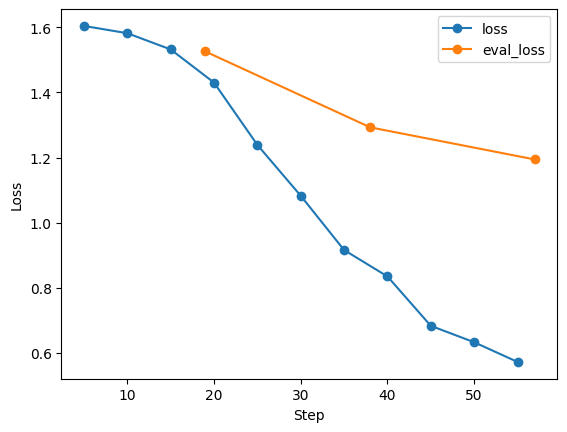

In [4]:
torch.cuda.reset_peak_memory_stats(); start=time.perf_counter()
trainer.train(); elapsed=time.perf_counter()-start; peak=torch.cuda.max_memory_allocated()/1024**3
print(f'Час {elapsed:.1f} с; пікова GPU пам’ять {peak:.2f} GiB')
h=pd.DataFrame(trainer.state.log_history); display(h)
for col in ['loss','eval_loss']:
 if col in h: plt.plot(h.dropna(subset=[col])['step'],h.dropna(subset=[col])[col],marker='o',label=col)
plt.xlabel('Step');plt.ylabel('Loss');plt.legend();plt.show()

In [5]:
pred=trainer.predict(ds['test']).predictions.argmax(-1); after=metrics(y,pred)
print(pd.DataFrame([base,after],index=['До: majority','Після: fine-tuning']))
print(classification_report(y,pred,target_names=labels,zero_division=0))
comparison=pd.DataFrame({'text':ds['test']['text'],'target':[labels[i] for i in y],'before':[labels[i] for i in before],'after':[labels[i] for i in pred]})
display(comparison.groupby('target').head(2)); errors=comparison[comparison.target!=comparison.after];display(errors.head(10))

                    accuracy        f1
До: majority             0.2  0.066667
Після: fine-tuning       0.6  0.596435
                   precision    recall  f1-score   support

      Авторизація       0.40      0.50      0.44        20
           Оплата       0.71      0.50      0.59        20
Технічна проблема       1.00      0.50      0.67        20
     Налаштування       0.57      1.00      0.73        20
       Пропозиція       0.62      0.50      0.56        20

         accuracy                           0.60       100
        macro avg       0.66      0.60      0.60       100
     weighted avg       0.66      0.60      0.60       100



,text,target,before,after
0,Пише неправильний пароль,Авторизація,Авторизація,Авторизація
1,Вітаю! Пише неправильний пароль,Авторизація,Авторизація,Авторизація
20,Де мій рахунок,Оплата,Авторизація,Налаштування
21,Вітаю! Де мій рахунок,Оплата,Авторизація,Налаштування
40,Зображення не відображаються,Технічна проблема,Авторизація,Технічна проблема
41,Вітаю! Зображення не відображаються,Технічна проблема,Авторизація,Технічна проблема
60,Як увімкнути темну тему,Налаштування,Авторизація,Налаштування
61,Вітаю! Як увімкнути темну тему,Налаштування,Авторизація,Налаштування
80,Пропоную покращити меню,Пропозиція,Авторизація,Налаштування
81,Вітаю! Пропоную покращити меню,Пропозиція,Авторизація,Налаштування


,text,target,before,after
10,Не пускає в особистий кабінет,Авторизація,Авторизація,Пропозиція
11,Вітаю! Не пускає в особистий кабінет,Авторизація,Авторизація,Пропозиція
12,"Підкажіть, будь ласка: Не пускає в особистий к...",Авторизація,Авторизація,Пропозиція
13,Маю питання: Не пускає в особистий кабінет,Авторизація,Авторизація,Оплата
14,Допоможіть: Не пускає в особистий кабінет,Авторизація,Авторизація,Пропозиція
15,"Добрий день, Не пускає в особистий кабінет",Авторизація,Авторизація,Пропозиція
16,Звертаюся щодо проблеми: Не пускає в особистий...,Авторизація,Авторизація,Оплата
17,Потрібна допомога. Не пускає в особистий кабінет,Авторизація,Авторизація,Пропозиція
18,Прошу розглянути: Не пускає в особистий кабінет,Авторизація,Авторизація,Оплата
19,Буду вдячний за відповідь: Не пускає в особист...,Авторизація,Авторизація,Оплата


## 1.6. Мій звіт

**Задача і чому потрібне донавчання:** маршрутизація українських звернень за п’ятьма фіксованими категоріями без генеративного промпту. RAG не навчає межі класів.

**Модель і дані:** multilingual DistilBERT, 500 синтетичних прикладів (300/100/100), різні основні формулювання між наборами. Шаблонність обмежує репрезентативність.

**Метрика й результат до донавчання:** baseline найчастішого класу, accuracy 0,20, macro F1 0,0667.

**Метод і гіперпараметри:** повне донавчання з новою головою, 3 епохи, LR 3e-5, batch 16, 57 кроків, fp16, Tesla T4. Час 7,8 с, пікова пам’ять 2,04 GiB. Validation loss за епохами: 1,5258 → 1,2929 → 1,1941; validation accuracy: 31% → 49% → 67%. Явного зростання validation loss немає, хоча розрив із training loss вимагає уваги.

**Результат після донавчання:** accuracy 60%, macro F1 0,596; приріст accuracy 40 відсоткових пунктів.

**Аналіз помилок:** 40 зі 100 прикладів помилкові. Наприклад, «Не пускає в особистий кабінет» та варіанти з привітаннями віднесено до пропозицій або оплати замість авторизації. Можлива причина — мала кількість незалежних формулювань. Для покращення потрібні різноманітні реальні розмічені звернення та окремий тестовий набір.

**Висновок:** донавчання покращило результат на синтетичному тесті, але 60% недостатньо для автономної маршрутизації без контролю оператора. Попередження про залежності pip не зупинили виконання.


In [6]:
print(f"До: accuracy={base['accuracy']:.3f}, F1={base['f1']:.3f}; після: accuracy={after['accuracy']:.3f}, F1={after['f1']:.3f}.")
print(f"Тренування: {elapsed:.1f} с, peak {peak:.2f} GiB. Помилок: {len(errors)} з {len(y)}.")
print('Висновок:', 'Донавчання покращило accuracy на цьому наборі.' if after['accuracy']>base['accuracy'] else 'Покращення accuracy не підтверджено.')
print('Обмеження: синтетичні дані; потрібна перевірка на реальних зверненнях.')

До: accuracy=0.200, F1=0.067; після: accuracy=0.600, F1=0.596.
Тренування: 7.8 с, peak 2.04 GiB. Помилок: 40 з 100.
Висновок: Донавчання покращило accuracy на цьому наборі.
Обмеження: синтетичні дані; потрібна перевірка на реальних зверненнях.
